![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Spatial Weights, Autocorrelation, Hot Spots and Clustering for Large Data

Spatial statistics ask how values relate to the values around them. Moran's I, local indicators
of spatial association (LISA) and Getis-Ord hot spots are routine for a few hundred counties, but
their cost grows quickly: every observation needs its neighbours, and significance comes from 999
random permutations of the data. With a million building footprints, a naive implementation runs
for hours. This notebook computes spatial weights, global and local autocorrelation, hot spots,
density-based clusters and kernel density surfaces with `geolattice.distributed.analysis`, checks
every statistic against PySAL's `esda`, and measures how the cost grows from a thousand to a
million observations on the CPU and on the GPU.

## Overview

### Why spatial statistics get expensive

| Step | Naive cost | What makes it tractable |
|---|---|---|
| Spatial weights | compare every pair: `n^2` | k-nearest neighbours with a KD-tree, contiguity with a spatial join: about `n log n` |
| Global statistic (Moran's I) | one sparse product `z' W z` | cheap: proportional to the number of neighbour pairs |
| 999 permutations of a global statistic | 999 sparse products | batch the permutations as columns of one matrix: a few sparse matrix products |
| Local statistics (LISA, G*) with permutations | 999 permutations for each of `n` observations | conditional permutation with shared random draws, computed in blocks |

### Spatial weights

A weights matrix `W` lists, for each observation, its neighbours: polygons that share an edge
(**rook**) or a point (**queen**), the `k` nearest points (**knn**), or all points within a
distance (**distance band**, binary or inverse distance). It is stored **sparse**: a million
observations with 8 neighbours each need 8 million entries, not 10^12. **Row standardisation**
divides each row by its sum, so the spatial lag `W y` is the mean of the neighbours.

### Global and local statistics

- **Moran's I**: `I = (n / S0) (z' W z) / (z' z)`, with `z` the deviations from the mean. Positive
  when similar values cluster.
- **Geary's C**: based on squared differences between neighbours; below 1 means positive
  autocorrelation.
- **Local Moran's I (LISA)**: `I_i = z_i (W z)_i / m2`, one value per observation, with quadrants
  HH (high among high), LL, HL and LH.
- **Getis-Ord G\***: the share of the total in each neighbourhood (including the observation
  itself), as a z-score: positive for hot spots, negative for cold spots.

Inference compares the observed statistic with its distribution under random permutations of the
values (the pseudo p-value `p_sim`), or with a normal approximation.

### Clustering points

- **DBSCAN** groups points that have at least `min_samples` neighbours within `eps`; the rest is
  noise. One distance scale for all clusters.
- **HDBSCAN** builds DBSCAN for every `eps` at once and keeps the most stable clusters; it finds
  dense and sparse clusters together.
- **k-means** splits points into `k` groups around centres; every point belongs to a group.
- **Kernel density estimation (KDE)** spreads each point over a smooth kernel and sums them on a
  grid.

## Spatial Statistics with GeoLattice

| Function | Returns | Engine (CPU / GPU) |
|---|---|---|
| `pdist.analysis.weights(gdf, kind=, k=, threshold=)` | a `Weights` object (SciPy CSR matrix, ids) | KD-tree or partitioned `sjoin` / CuPy knn |
| `morans_i`, `gearys_c` | `GlobalResult` with statistic, expectation, variance, `z_norm`, `p_norm`, `p_sim` | batched permutations with NumPy / CuPy sparse products |
| `local_morans`, `getis_ord_local` | DataFrame with one row per observation | conditional permutations in blocks, NumPy / CuPy |
| `dbscan`, `hdbscan`, `kmeans` | cluster labels (and centres) | scikit-learn / cuML |
| `kde(points, like, bandwidth=)` | density surface on the grid of `like` | chunk by chunk, NumPy / CuPy |

`Weights` has `row_standardize()`, `binary()`, `cardinalities`, `islands`, `to_libpysal()` and
`to_gpu()`. Statistics equal `esda`'s for the same weights; permutation p-values agree in
distribution (the random draws differ).

### Learning objectives

1. Explain why spatial statistics scale badly without sparse weights and batched permutations.
2. Build queen, rook and k-nearest-neighbour weights and compare them with `libpysal`.
3. Compute Moran's I, Geary's C, LISA and G* and check them against `esda`.
4. Measure how the cost grows from 10^3 to 10^6 observations on CPU and GPU.
5. Cluster building centroids with DBSCAN, HDBSCAN and k-means, and compare scikit-learn with
   cuML.
6. Compute a kernel density surface of 1.6 million buildings.

### Data

| Dataset | Content |
|---|---|
| Great Plains counties | 225 polygons; mean NDVI of each from the 90 m raster (`pdist.zonal_stats`) |
| Kansas building footprints | 1.6 million polygons; centroids and footprint areas |

### Contents

- Setup
- Weights for counties
- Global autocorrelation of county NDVI
- Local statistics: LISA clusters and hot spots
- From a thousand to a million observations
- Settlements from building centroids
- Building density surface
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import esda  # PySAL exploratory spatial data analysis, the reference
import libpysal  # PySAL weights
from sklearn.metrics import adjusted_rand_score  # agreement of two clusterings


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


def timed(fn):  # wall time and result of one call
    t = time.perf_counter(); out = fn(); sync(); return time.perf_counter() - t, out  # time it

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## Weights for counties

Queen and rook contiguity for the 225 Great Plains counties come from a partitioned spatial join
with the `touches` predicate (rook keeps pairs that share a boundary segment, not just a point).
`libpysal` computes the same from the polygons' shared vertices.

In [2]:
counties = dd.gp_counties()  # 225 counties, EPSG:5070
wq = pdist.analysis.weights(counties, "queen")  # queen contiguity, row-standardised
wr = pdist.analysis.weights(counties, "rook")  # rook contiguity
wk = pdist.analysis.weights(counties, "knn", k=6)  # 6 nearest centroids
lq = libpysal.weights.Queen.from_dataframe(counties, use_index=False)  # the reference
lr = libpysal.weights.Rook.from_dataframe(counties, use_index=False)  # the reference
same = lambda w, l: (w.binary().sparse != l.sparse).nnz == 0  # identical neighbour sets?
print(f"queen: mean {wq.cardinalities.mean():.2f} neighbours, islands {len(wq.islands)}, same as libpysal: {same(wq, lq)}")  # queen
print(f"rook:  mean {wr.cardinalities.mean():.2f} neighbours, same as libpysal: {same(wr, lr)}")  # rook
print(f"knn:   {wk.cardinalities.min()} to {wk.cardinalities.max()} neighbours, {wk.sparse.nnz} entries")  # knn

queen: mean 5.39 neighbours, islands 0, same as libpysal: True
rook:  mean 5.19 neighbours, same as libpysal: True
knn:   6 to 6 neighbours, 1350 entries


GeoLattice and libpysal find the same neighbours. Queen counties have one more neighbour on
average than rook counties: the corner contacts of the township and range grid, where four
counties meet at a point.

## Global autocorrelation of county NDVI

The variable is each county's mean NDVI, from `pdist.zonal_stats` on the 262 million pixel NDVI
raster.

In [3]:
ndvi = pdist.zonal_stats(counties, dd.gp_raster("ndvi"), stats=["mean"])["mean"].values  # county mean NDVI
wl = wq.to_libpysal()  # the same weights as a libpysal W
wl.transform = "r"  # row-standardised, as wq
mi = pdist.analysis.morans_i(ndvi, wq, permutations=999, seed=0)  # GeoLattice
ref = esda.Moran(ndvi, wl, permutations=999)  # esda
gc = pdist.analysis.gearys_c(ndvi, wq, permutations=999, seed=0)  # GeoLattice Geary
gref = esda.Geary(ndvi, wl, permutations=999)  # esda Geary
pd.DataFrame({"GeoLattice": [mi.statistic, mi.expected, mi.variance_norm, mi.z_norm, mi.p_sim, gc.statistic, gc.z_norm, gc.p_sim],  # ours
              "esda": [ref.I, ref.EI, ref.VI_norm, ref.z_norm, ref.p_sim, gref.C, gref.z_rand, gref.p_sim]},  # theirs (Geary z under randomisation)
             index=["Moran I", "E[I]", "Var[I] (normal)", "z (normal)", "p_sim", "Geary C", "Geary z (randomisation)", "Geary p_sim"]).round(5)  # table

,GeoLattice,esda
Moran I,0.86805,0.86805
E[I],-0.00446,-0.00446
Var[I] (normal),0.00171,0.00171
z (normal),21.11459,21.11459
p_sim,0.00100,0.00100
Geary C,0.13319,0.13319
Geary z (randomisation),-20.36067,-20.36067
Geary p_sim,0.00100,0.00100


The statistics, their expectations, variances and z-scores are identical; the permutation
p-values are both the smallest possible with 999 permutations (0.001), because no permutation came
near the observed value. County NDVI is strongly autocorrelated (I near 0.9): the gradient from
the humid east to the dry west dominates.

## Local statistics: LISA clusters and hot spots

In [4]:
lisa = pdist.analysis.local_morans(ndvi, wq, permutations=999, seed=0)  # LISA
lref = esda.Moran_Local(ndvi, wl, permutations=999, seed=0)  # esda
g = pdist.analysis.getis_ord_local(ndvi, wq, star=True)  # G*
gref = esda.G_Local(ndvi, wq.binary().to_libpysal(), transform="B", star=True, permutations=0)  # esda G* with binary weights, as GeoLattice
print("LISA Is equal to esda:", np.allclose(lisa.Is, lref.Is), "| quadrants equal:", bool((lisa.q.values == lref.q).all()))  # check
print("G* z-scores equal to esda:", np.allclose(g.Zs, gref.Zs))  # check
print(f"significant LISA (p_sim < 0.05): GeoLattice {int((lisa.p_sim < 0.05).sum())}, esda {int((lref.p_sim < 0.05).sum())}")  # inference

LISA Is equal to esda: True | quadrants equal: True
G* z-scores equal to esda: True
significant LISA (p_sim < 0.05): GeoLattice 99, esda 94


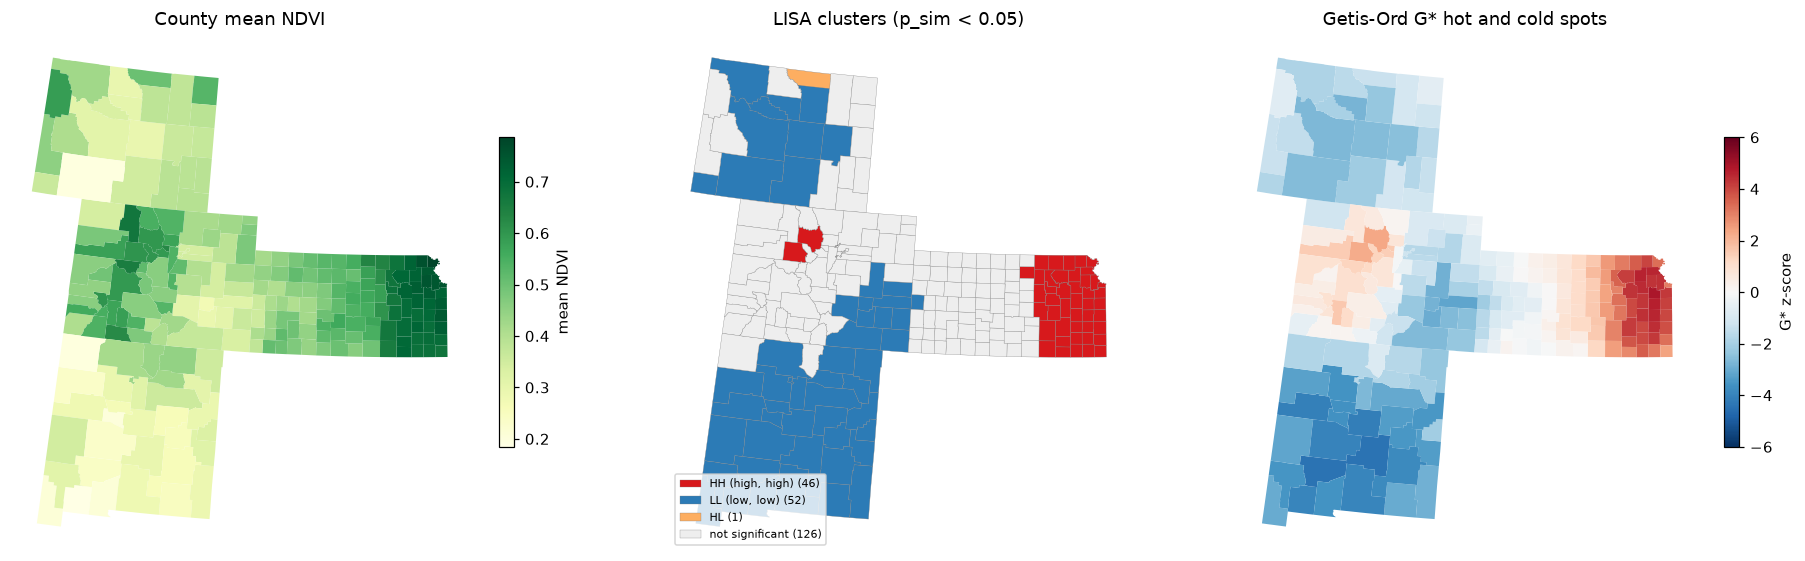

In [5]:
lab = {1: "HH (high, high)", 2: "LH", 3: "LL (low, low)", 4: "HL"}  # quadrant names
counties["ndvi"] = ndvi  # county mean NDVI
counties["lisa"] = np.where(lisa.p_sim < 0.05, lisa.q.map(lab), "not significant")  # significant quadrants
counties["gstar"] = g.Zs.values  # hot spot z-scores
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))  # three maps
counties.plot("ndvi", ax=ax[0], cmap="YlGn", legend=True, legend_kwds={"shrink": 0.6, "label": "mean NDVI"})  # variable
colors = {"HH (high, high)": "#d7191c", "LL (low, low)": "#2c7bb6", "LH": "#abd9e9", "HL": "#fdae61", "not significant": "#eeeeee"}  # palette
for k, v in colors.items():  # one layer per class
    sub = counties[counties.lisa == k]  # its counties
    if len(sub):  # draw if any
        sub.plot(ax=ax[1], color=v, edgecolor="grey", linewidth=0.2, label=f"{k} ({len(sub)})")  # map
ax[1].legend(fontsize=7, loc="lower left")  # legend
counties.plot("gstar", ax=ax[2], cmap="RdBu_r", vmin=-6, vmax=6, legend=True, legend_kwds={"shrink": 0.6, "label": "G* z-score"})  # hot spots
for a, t in zip(ax, ["County mean NDVI", "LISA clusters (p_sim < 0.05)", "Getis-Ord G* hot and cold spots"]):  # titles
    a.set_title(t); a.set_axis_off()  # labels
plt.tight_layout(); plt.show()  # draw

The local values equal esda's; the counts of significant counties differ slightly because the
permutations use different random draws. Eastern Kansas forms a high-high cluster and hot spot of
vegetation, joined by a small high-high cluster of forested counties in the Colorado mountains.
New Mexico, most of Wyoming and the dry plains of south-eastern Colorado form low-low clusters and
cold spots.

## From a thousand to a million observations

The same statistics on Kansas buildings: the variable is the logarithm of footprint area, the
weights are the 8 nearest neighbours of each building's representative point. Samples of 10^3 to
10^6 buildings show how each step scales on the CPU and the GPU, with esda for comparison where it
finishes in reasonable time.

In [6]:
bld = pdist.vector.to_crs(dd.kansas_buildings(), 5070)  # 1.6 million buildings in metres
bld["log_area"] = np.log(pdist.vector.area(bld))  # log footprint area
pts = bld.set_geometry(bld.geometry.representative_point())  # one point per building
rows = []  # timings
for n in [1_000, 10_000, 100_000, 1_000_000]:  # sample sizes
    s = pts.sample(n, random_state=0)  # random sample
    y = s.log_area.values  # the variable
    r = {"n": n}  # one row
    r["weights knn CPU"], w = timed(lambda: pdist.analysis.weights(s, "knn", k=8, compute="cpu"))  # KD-tree
    if caps["gpus"] and n <= 100_000:  # GPU knn is brute force: n x n distances, so only up to 10^5
        r["weights knn GPU"], _ = timed(lambda: pdist.analysis.weights(s, "knn", k=8, compute="gpu"))  # brute force
    r["Moran 999 CPU"], m_c = timed(lambda: pdist.analysis.morans_i(y, w, permutations=999, seed=0, compute="cpu"))  # batched permutations
    if caps["gpus"]:  # GPU Moran
        r["Moran 999 GPU"], m_g = timed(lambda: pdist.analysis.morans_i(y, w, permutations=999, seed=0, compute="gpu"))  # on the GPU
    r["LISA 999 CPU"], _ = timed(lambda: pdist.analysis.local_morans(y, w, permutations=999, seed=0, compute="cpu"))  # local
    if caps["gpus"]:  # GPU LISA
        r["LISA 999 GPU"], _ = timed(lambda: pdist.analysis.local_morans(y, w, permutations=999, seed=0, compute="gpu"))  # local on GPU
    if n <= 100_000:  # esda for the smaller samples
        wl = w.to_libpysal(); wl.transform = "r"  # same weights
        r["esda Moran 999"], e = timed(lambda: esda.Moran(y, wl, permutations=999))  # reference
        r["esda LISA 999"], _ = timed(lambda: esda.Moran_Local(y, wl, permutations=999, n_jobs=-1, seed=0))  # reference
        r["I equals esda"] = bool(np.isclose(m_c.statistic, e.I))  # check
    r["Moran I"] = m_c.statistic  # the statistic
    rows.append(r)  # keep
scale = pd.DataFrame(rows).set_index("n")  # table
scale.round(3)  # show

,weights knn CPU,weights knn GPU,Moran 999 CPU,Moran 999 GPU,LISA 999 CPU,LISA 999 GPU,esda Moran 999,esda LISA 999,I equals esda,Moran I
n,,,,,,,,,,
1000,0.005,0.024,0.023,0.014,0.069,0.014,0.022,31.623,True,0.107
10000,0.016,0.099,0.316,0.041,0.698,0.130,0.177,0.358,True,0.100
100000,0.142,7.869,3.682,0.392,7.055,1.302,2.185,4.363,True,0.169
1000000,1.754,NaN,48.478,4.967,73.707,14.789,NaN,NaN,NaN,0.246


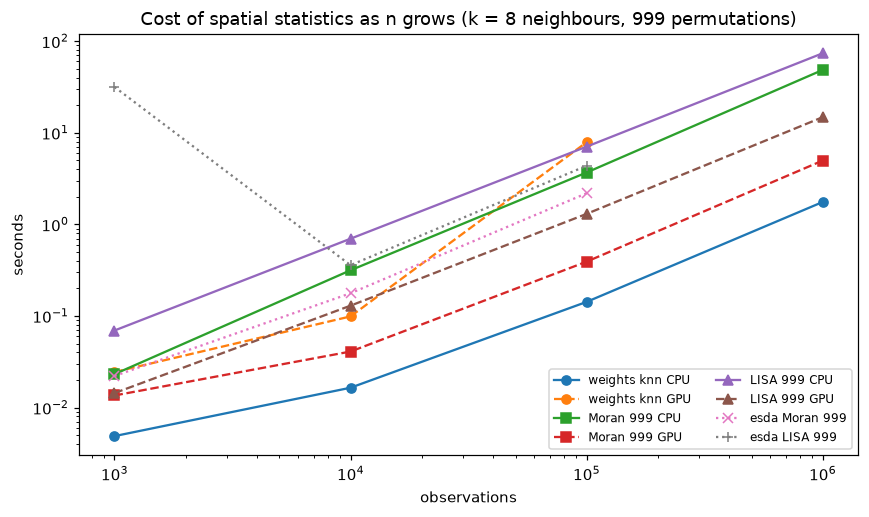

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))  # one panel
for col, style in [("weights knn CPU", "o-"), ("weights knn GPU", "o--"), ("Moran 999 CPU", "s-"), ("Moran 999 GPU", "s--"), ("LISA 999 CPU", "^-"),  # series
                   ("LISA 999 GPU", "^--"), ("esda Moran 999", "x:"), ("esda LISA 999", "+:")]:  # esda
    if col in scale:  # present on this machine
        ax.loglog(scale.index, scale[col], style, label=col)  # time against n
ax.set_xlabel("observations"); ax.set_ylabel("seconds"); ax.legend(fontsize=8, ncol=2)  # labels
ax.set_title("Cost of spatial statistics as n grows (k = 8 neighbours, 999 permutations)"); plt.tight_layout(); plt.show()  # draw

All costs grow roughly linearly with `n`, which is what sparse weights and batched permutations
buy. The exception is the GPU's brute-force nearest-neighbour search, which compares every pair
and grows with `n^2`; it was run only up to 10^5 points, and the KD-tree is the right tool beyond
that. On the CPU, GeoLattice's batched permutations were somewhat slower than esda, whose
permutation loops are compiled with numba (esda's very first LISA call, at 10^3, includes about
half a minute of that compilation). On the GPU the same batched algorithm was about ten times
faster than the CPU for Moran's I and about five times faster for LISA, and it finished the
million-building case (999 permutations, 8 neighbours each) in seconds. The statistic itself
agreed with esda at every size where esda was run. Building sizes are positively but weakly
autocorrelated (I of 0.1 to 0.25, higher in the denser samples): neighbouring buildings tend to be
of similar size, as in subdivisions, farmsteads and industrial parks.

## Settlements from building centroids

Clusters of buildings are settlements. DBSCAN with `eps` = 100 m and 20 buildings finds compact
built-up areas; HDBSCAN adapts to varying density. The 270,000 buildings of the Wichita area are
clustered on the CPU (scikit-learn) and on the GPU (cuML), and the two labelings compared with
the adjusted Rand index (1 = identical partitions).

In [8]:
x0, y0 = gpd.GeoSeries.from_xy([-97.34], [37.69], crs=4326).to_crs(5070).iloc[0].coords[0]  # central Wichita
area = pts.cx[x0 - 40_000:x0 + 40_000, y0 - 40_000:y0 + 40_000]  # 80 x 80 km
print(f"{len(area):,} buildings")  # size
res = {}  # timings
res["DBSCAN CPU"], db_c = timed(lambda: pdist.analysis.dbscan(area, eps=100, min_samples=20, compute="cpu"))  # scikit-learn
if caps["gpus"]:  # cuML
    res["DBSCAN GPU"], db_g = timed(lambda: pdist.analysis.dbscan(area, eps=100, min_samples=20, compute="gpu"))  # opt-in GPU
    print("DBSCAN CPU vs GPU adjusted Rand index:", round(adjusted_rand_score(db_c, db_g), 4))  # agreement
res["HDBSCAN CPU"], hd_c = timed(lambda: pdist.analysis.hdbscan(area, min_cluster_size=50, compute="cpu"))  # scikit-learn
if caps["gpus"]:  # cuML
    res["HDBSCAN GPU"], hd_g = timed(lambda: pdist.analysis.hdbscan(area, min_cluster_size=50, compute="gpu"))  # cuML
    print("HDBSCAN CPU vs GPU adjusted Rand index:", round(adjusted_rand_score(hd_c, hd_g), 4))  # agreement
res["k-means CPU"], (km_c, cen) = timed(lambda: pdist.analysis.kmeans(area, 12, compute="cpu"))  # 12 groups
if caps["gpus"]:  # cuML
    res["k-means GPU"], (km_g, _) = timed(lambda: pdist.analysis.kmeans(area, 12, compute="gpu"))  # 12 groups
for name, lab in [("DBSCAN", db_c), ("HDBSCAN", hd_c)]:  # cluster counts
    print(f"{name}: {lab.max() + 1} clusters, {(lab < 0).mean():.1%} noise")  # summary
pd.Series(res, name="seconds").round(3).to_frame()  # table

271,988 buildings


[2026-11-24 09:06:37.421] [CUML] [info] Batch size limited by the chosen integer type (4 bytes). 9855 -> 7895. Using the larger integer type might result in better performance


DBSCAN CPU vs GPU adjusted Rand index: 1.0


HDBSCAN CPU vs GPU adjusted Rand index: 0.7093


DBSCAN: 670 clusters, 33.2% noise
HDBSCAN: 324 clusters, 26.4% noise


,seconds
DBSCAN CPU,0.542
DBSCAN GPU,25.137
HDBSCAN CPU,124.958
HDBSCAN GPU,7.073
k-means CPU,2.234
k-means GPU,1.553


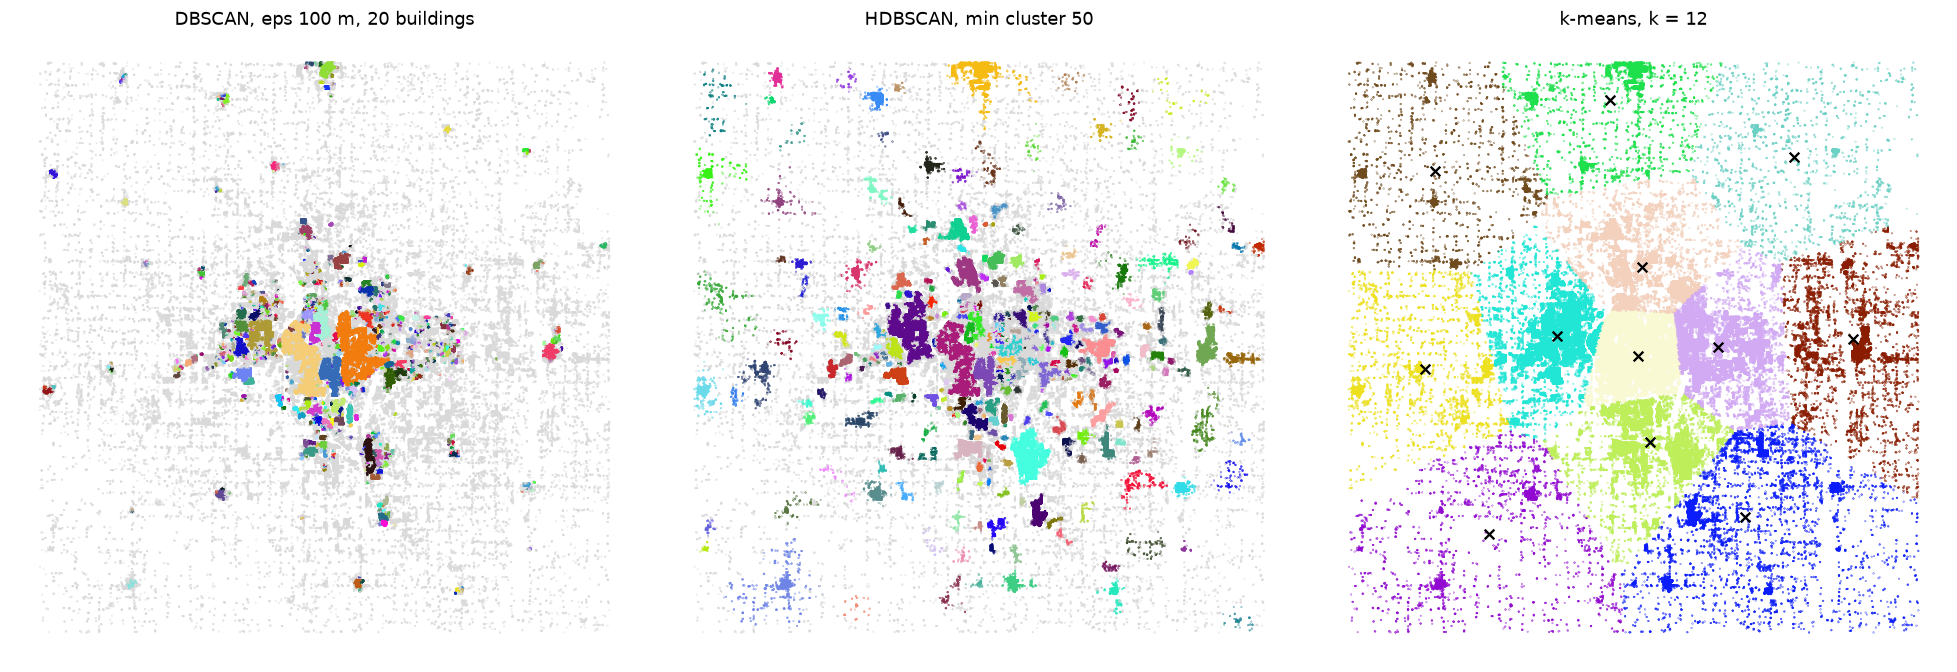

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))  # three maps
rng = np.random.default_rng(1)  # random colours
for a, lab, t in [(ax[0], db_c, "DBSCAN, eps 100 m, 20 buildings"), (ax[1], hd_c, "HDBSCAN, min cluster 50"), (ax[2], km_c, "k-means, k = 12")]:  # panels
    cols = rng.random((int(lab.max()) + 2, 3))  # one colour per cluster
    c = np.where(lab.values[:, None] < 0, 0.85, cols[lab.values])  # grey for noise
    a.scatter(area.geometry.x, area.geometry.y, s=0.05, c=c)  # buildings
    a.set_title(t); a.set_aspect("equal"); a.set_axis_off()  # labels
ax[2].scatter(cen[:, 0], cen[:, 1], marker="x", color="k", s=40)  # k-means centres
plt.tight_layout(); plt.show()  # draw

DBSCAN separates Wichita and its suburbs from the surrounding small towns and farmsteads (grey
noise). HDBSCAN finds many more, smaller clusters, down to individual subdivisions and villages,
because it does not fix one density threshold. k-means is the odd one out: it must put every
building in one of 12 groups, so it cuts the city into slices instead of finding settlements.

The two engines behave very differently here, and the reasons matter.

- **DBSCAN**: the CPU and GPU labelings agree, but scikit-learn's KD-tree beats cuML's
  brute-force neighbour search on two-dimensional points by a wide margin. GeoLattice therefore
  keeps DBSCAN on the CPU unless `compute="gpu"` is asked for.
- **HDBSCAN**: cuML was about twenty times faster, but its partition differs from scikit-learn's
  (an adjusted Rand index of about 0.7 above). Two things were found while writing this
  notebook. First, on raw EPSG:5070 coordinates (values in the millions of metres) cuML lost
  precision and agreed with scikit-learn at an index near 0; GeoLattice now subtracts the mean
  of the coordinates before clustering, which changes nothing mathematically. Second, even on
  centred coordinates cuML builds its cluster hierarchy differently (it found fewer, larger
  clusters), while scikit-learn's result was stable to a 1 cm jitter of the points. cuML's
  HDBSCAN is therefore opt-in: use it when speed matters more than matching the reference
  implementation, and check its clusters.
- **k-means** gave the same groups on both, at similar speed.

## Building density surface

`pdist.analysis.kde` computes a kernel density surface on the grid of a template raster. Each
chunk receives only the points within the kernel's reach, so 1.6 million points and a statewide
grid stay manageable. Here a quartic kernel with a 3 km bandwidth on a 1 km grid covering Kansas.

compute=cpu: 23.8 s for 1,605,334 points on a 353 x 652 grid


compute=gpu: 3.2 s for 1,605,334 points on a 353 x 652 grid
integral 1,604,789 (should be close to 1,605,334)


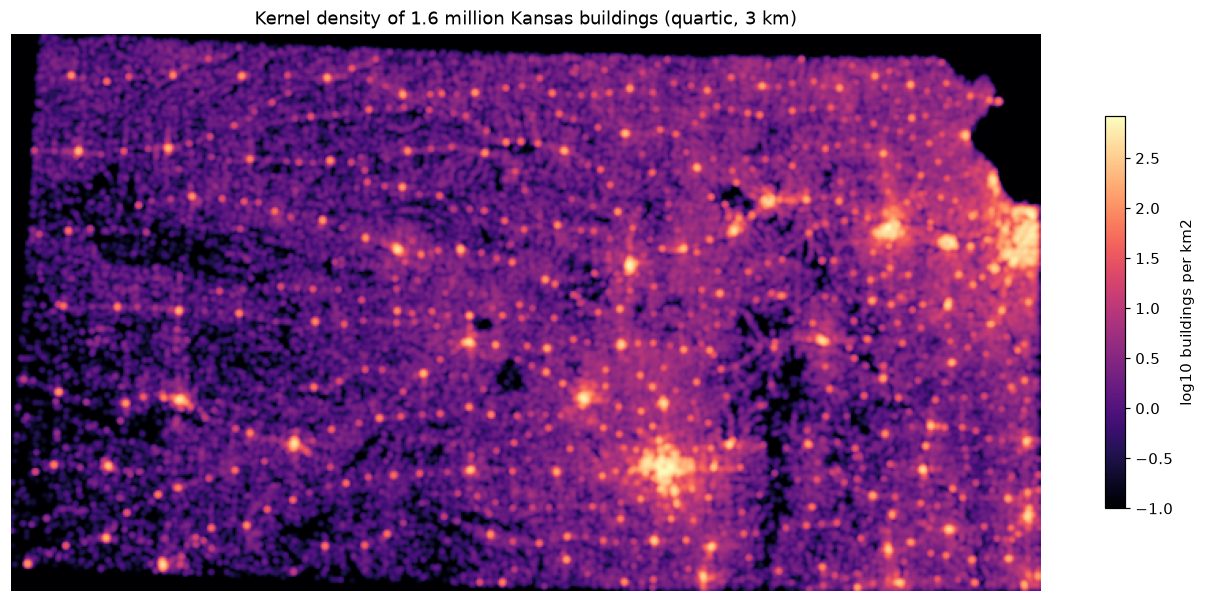

In [10]:
xmin, ymin, xmax, ymax = pts.total_bounds  # Kansas extent
xs = np.arange(xmin, xmax, 1000) + 500; ys = np.arange(ymax, ymin, -1000) - 500  # 1 km pixel centres
grid = xr.DataArray(np.zeros((len(ys), len(xs)), np.float32), dims=("y", "x"), coords={"y": ys, "x": xs}).rio.write_crs(5070)  # template
res = {}  # timings
for c in (["cpu", "gpu"] if caps["gpus"] else ["cpu"]):  # both targets
    res[c], dens = timed(lambda: pdist.analysis.kde(pts, grid, bandwidth=3000, kernel="quartic", compute=c, chunks=(64, 64)))  # density
    print(f"compute={c}: {res[c]:.1f} s for {len(pts):,} points on a {grid.shape[0]} x {grid.shape[1]} grid")  # time
dens_km2 = dens * 1e6  # buildings per km2
print(f"integral {float(dens.sum()) * 1e6:,.0f} (should be close to {len(pts):,})")  # check: density integrates to the count
fig, ax = plt.subplots(figsize=(12, 5.5))  # one map
im = ax.imshow(np.log10(dens_km2 + 0.1), extent=dd.extent(dens), cmap="magma")  # log density
plt.colorbar(im, ax=ax, shrink=0.7, label="log10 buildings per km2")  # scale
ax.set_title("Kernel density of 1.6 million Kansas buildings (quartic, 3 km)"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

The density integrates to the number of buildings (up to the kernels that spill over the state
border), a quick check that the surface is a proper density. The towns along the highways and
rivers, Wichita, Topeka, Lawrence and the Kansas City suburbs stand out against the sparse west.

## Summary and exercises

- Sparse weights, batched global permutations and blocked conditional permutations keep spatial
  statistics close to linear in the number of observations.
- GeoLattice's contiguity weights matched libpysal's, and Moran's I, Geary's C, LISA and G*
  matched esda; permutation p-values agree in distribution.
- From 10^3 to 10^6 buildings the cost grew roughly linearly. On the CPU esda was somewhat faster;
  the GPU was five to ten times faster than both and handled a million buildings in seconds.
- DBSCAN, HDBSCAN and k-means answer different questions about building clusters. cuML's HDBSCAN
  was much faster than scikit-learn's but found a different partition, so it is opt-in; for 2-D
  DBSCAN the CPU KD-tree is faster.
- A kernel density surface of 1.6 million points was computed chunk by chunk and integrates to the
  number of points.

**Exercises**

1. Repeat the county analysis with rook and knn (k = 4) weights. How much do Moran's I and the
   LISA map change?
2. Compute G* hot spots of building size for the 100,000 building sample and map them for
   Wichita.
3. Run DBSCAN with `eps` of 50, 100 and 200 m. How do the number of settlements and the noise
   share change?
4. Compute the KDE with a Gaussian kernel and a 1 km bandwidth on a 250 m grid for Sedgwick
   County. How do CPU and GPU times change with the bandwidth?